In [10]:
import scipy.signal as signal
import scipy.fft as fft
import scipy.stats as stats

import numpy as np
import matplotlib.pyplot as plt
import plotly.graph_objects as go
from plotly.subplots import make_subplots
import plotly.express as px
import pandas as pd
import glob 
import os
import pickle
import pywt #PyWavelets package
import matplotlib.colors as colors

# importing the pdr module itself is mandatory for most uses of pdr.
import pdr  
from data_process import select_df,fac_decompose_dB,read_and_process_data,detrend_data


## Verification of Meeks et al., 2016

### 21 DEC 2010 03:00-03:10

In [11]:
start_time=pd.to_datetime('2010-12-21 02:50:00')
end_time=pd.to_datetime('2010-12-21 03:20:00')

df=select_df(start_time,end_time)
df=read_and_process_data(start_time,end_time)

In [12]:
df

,TIME,BR,BTHETA,BPHI,BTOTAL,NPTS,B0_R,B0_THETA,B0_PHI,B0_TOTAL,...,dB_THETA,dB_PHI,dB_TOTAL,b_hat_R,b_hat_THETA,b_hat_PHI,dB_parallel,dB_perpendicular,dB_perpendicular_1,dB_perpendicular_2
0,2010-12-21 03:00:00.500,-3.981,190.717,-0.115,190.758,16,-4.133346,190.659878,-0.175117,190.704757,...,0.057122,0.060117,0.173454,-0.021674,0.999765,-0.000918,0.053751,0.164915,0.153547,-0.060169
1,2010-12-21 03:00:01.500,-4.109,190.753,0.013,190.798,16,-4.132668,190.643682,-0.175085,190.688550,...,0.109318,0.188085,0.218830,-0.021672,0.999765,-0.000918,0.108606,0.189977,0.026027,-0.188185
2,2010-12-21 03:00:02.500,-4.251,190.756,-0.064,190.804,16,-4.132125,190.627467,-0.174842,190.672326,...,0.128533,0.110842,0.207215,-0.021671,0.999765,-0.000917,0.130978,0.160570,-0.116064,-0.110960
3,2010-12-21 03:00:03.500,-4.201,190.706,-0.186,190.752,16,-4.131766,190.611191,-0.174665,190.656047,...,0.094809,-0.011335,0.117943,-0.021671,0.999765,-0.000916,0.096298,0.068098,-0.067163,0.011248
4,2010-12-21 03:00:04.500,-4.050,190.651,-0.235,190.695,16,-4.131389,190.594957,-0.174733,190.639809,...,0.056043,-0.060267,0.115746,-0.021671,0.999765,-0.000917,0.054321,0.102207,0.082586,0.060215
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
595,2010-12-21 03:09:55.500,-3.849,180.950,-0.307,180.991,8,-3.790669,181.261327,-0.160054,181.301030,...,-0.311327,-0.146946,0.349170,-0.020908,0.999781,-0.000883,-0.309909,0.160861,-0.064825,0.147221
596,2010-12-21 03:09:56.500,-3.905,180.971,-0.297,181.013,8,-3.790041,181.245952,-0.159893,181.285645,...,-0.274952,-0.137107,0.328043,-0.020906,0.999781,-0.000882,-0.272367,0.182835,-0.120680,0.137350
597,2010-12-21 03:09:57.500,-3.968,181.021,-0.347,181.065,8,-3.789462,181.230517,-0.159436,181.270201,...,-0.209517,-0.187564,0.333097,-0.020905,0.999781,-0.000880,-0.205573,0.262094,-0.182876,0.187748
598,2010-12-21 03:09:58.500,-3.948,181.074,-0.375,181.117,8,-3.789223,181.215108,-0.158832,181.254789,...,-0.141108,-0.216168,0.303068,-0.020906,0.999781,-0.000876,-0.137568,0.270047,-0.161688,0.216292


In [13]:
fig=make_subplots(rows=4,cols=1,

                  shared_xaxes='all',
                  shared_yaxes='all',
                  vertical_spacing=0.01)
fig.add_trace(go.Scatter(x=pd.to_datetime(df['TIME']),y=df['dB_R'],mode='lines',
                        #  name='BR',
                         line=dict(color='blue')),row=1,col=1)
fig.add_trace(go.Scatter(x=pd.to_datetime(df['TIME']),y=df['dB_THETA'],mode='lines',
                        #  name='BTHETA',
                         line=dict(color='blue')),row=2,col=1)
fig.add_trace(go.Scatter(x=pd.to_datetime(df['TIME']),y=df['dB_PHI'],mode='lines',
                        #  name='BPHI',
                         line=dict(color='blue')),row=3,col=1)
fig.add_trace(go.Scatter(x=pd.to_datetime(df['TIME']),y=df['dB_TOTAL'],mode='lines',
                        #  name='BTOTAL',
                         line=dict(color='blue')),row=4,col=1)

# set ylim for all subplots to be the same
fig.update_yaxes(range=[-2,2])

fig.update_xaxes(title_text="Time",row=4,col=1)
fig.update_yaxes(title_text="BR (nT)",row=1,col=1)
fig.update_yaxes(title_text="BTHETA (nT)",row=2,col=1)
fig.update_yaxes(title_text="BPHI (nT)",row=3,col=1)
fig.update_yaxes(title_text="BTOTAL (nT)",row=4,col=1)


#center title
fig.update_layout(height=800,title_text="Detrended Magnetic Field Components from 2010-12-21 02:50:00 to 2010-12-21 03:20:00",title_x=0.4)
fig.show()

In [14]:
df

,TIME,BR,BTHETA,BPHI,BTOTAL,NPTS,B0_R,B0_THETA,B0_PHI,B0_TOTAL,...,dB_THETA,dB_PHI,dB_TOTAL,b_hat_R,b_hat_THETA,b_hat_PHI,dB_parallel,dB_perpendicular,dB_perpendicular_1,dB_perpendicular_2
0,2010-12-21 03:00:00.500,-3.981,190.717,-0.115,190.758,16,-4.133346,190.659878,-0.175117,190.704757,...,0.057122,0.060117,0.173454,-0.021674,0.999765,-0.000918,0.053751,0.164915,0.153547,-0.060169
1,2010-12-21 03:00:01.500,-4.109,190.753,0.013,190.798,16,-4.132668,190.643682,-0.175085,190.688550,...,0.109318,0.188085,0.218830,-0.021672,0.999765,-0.000918,0.108606,0.189977,0.026027,-0.188185
2,2010-12-21 03:00:02.500,-4.251,190.756,-0.064,190.804,16,-4.132125,190.627467,-0.174842,190.672326,...,0.128533,0.110842,0.207215,-0.021671,0.999765,-0.000917,0.130978,0.160570,-0.116064,-0.110960
3,2010-12-21 03:00:03.500,-4.201,190.706,-0.186,190.752,16,-4.131766,190.611191,-0.174665,190.656047,...,0.094809,-0.011335,0.117943,-0.021671,0.999765,-0.000916,0.096298,0.068098,-0.067163,0.011248
4,2010-12-21 03:00:04.500,-4.050,190.651,-0.235,190.695,16,-4.131389,190.594957,-0.174733,190.639809,...,0.056043,-0.060267,0.115746,-0.021671,0.999765,-0.000917,0.054321,0.102207,0.082586,0.060215
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
595,2010-12-21 03:09:55.500,-3.849,180.950,-0.307,180.991,8,-3.790669,181.261327,-0.160054,181.301030,...,-0.311327,-0.146946,0.349170,-0.020908,0.999781,-0.000883,-0.309909,0.160861,-0.064825,0.147221
596,2010-12-21 03:09:56.500,-3.905,180.971,-0.297,181.013,8,-3.790041,181.245952,-0.159893,181.285645,...,-0.274952,-0.137107,0.328043,-0.020906,0.999781,-0.000882,-0.272367,0.182835,-0.120680,0.137350
597,2010-12-21 03:09:57.500,-3.968,181.021,-0.347,181.065,8,-3.789462,181.230517,-0.159436,181.270201,...,-0.209517,-0.187564,0.333097,-0.020905,0.999781,-0.000880,-0.205573,0.262094,-0.182876,0.187748
598,2010-12-21 03:09:58.500,-3.948,181.074,-0.375,181.117,8,-3.789223,181.215108,-0.158832,181.254789,...,-0.141108,-0.216168,0.303068,-0.020906,0.999781,-0.000876,-0.137568,0.270047,-0.161688,0.216292


In [15]:
cyclotron_freq=  (190e-9 * 1.6e-19) /(2*np.pi* 18*1.66e-27 ) # H2O+
# 2 pi m / (q B) where m is the mass of the particle, q is the charge, and B is the magnetic field strength. For a proton in a 18 nT field, this gives us a cyclotron frequency of approximately 1.7 Hz.
cyclotron_freq

0.16192470783111174

In [16]:
#plot B0_R, B0_THETA, B0_PHI
fig=go.Figure()
fig.add_trace(go.Scatter(x=pd.to_datetime(df['TIME']),y=df['B0_R'],mode='lines',name='B0_R'))
fig.add_trace(go.Scatter(x=pd.to_datetime(df['TIME']),y=df['B0_THETA'],mode='lines',name='B0_THETA'))
fig.add_trace(go.Scatter(x=pd.to_datetime(df['TIME']),y=df['B0_PHI'],mode='lines',name='B0_PHI'))
fig.update_layout(height=400,title_text="Background Magnetic Field Components")
fig.show()  

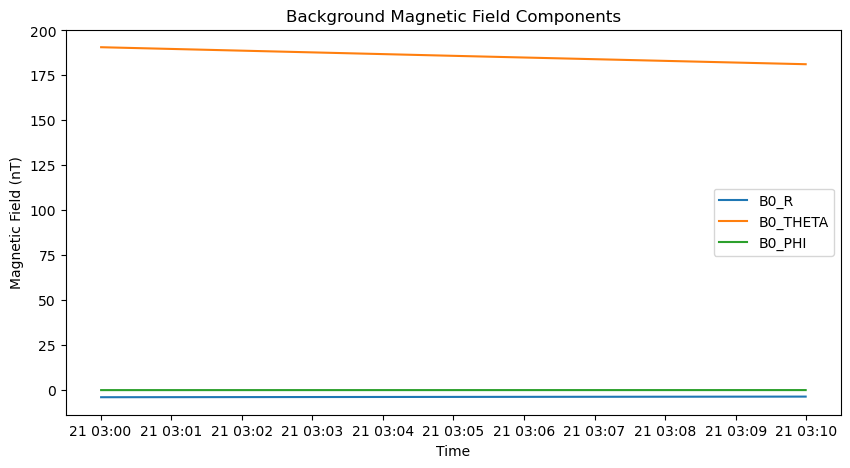

In [17]:
#plot B0_R, B0_THETA, B0_PHI
fig,ax=plt.subplots(figsize=(10,5))
ax.plot(df['TIME'],df['B0_R'],label='B0_R')
ax.plot(df['TIME'],df['B0_THETA'],label='B0_THETA')
ax.plot(df['TIME'],df['B0_PHI'],label='B0_PHI')
ax.set_title("Background Magnetic Field Components")
ax.set_xlabel("Time")
ax.set_ylabel("Magnetic Field (nT)")
ax.legend()
plt.show()

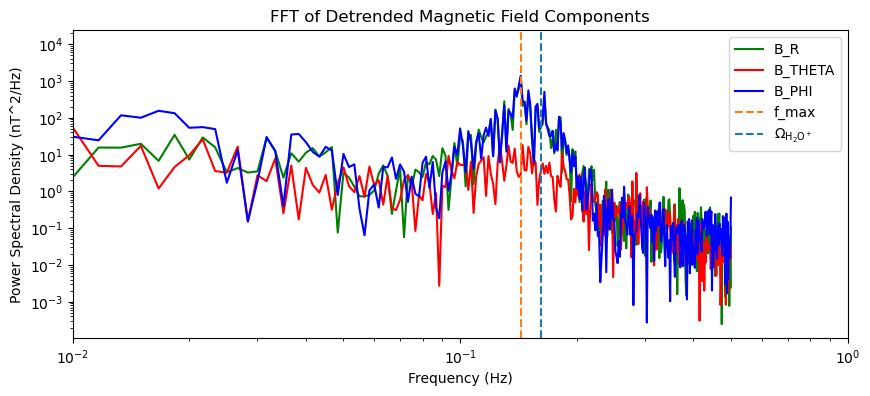

In [20]:
# do a FFT on the BR, BTHETA, BPHI, BTOTAL components and plot the spectrum
col=['dB_R','dB_THETA','dB_PHI']
F_list=[]
for c in col:
    fn=df[c].values
    N=len(fn)
    T=1/df['TIME'].diff().dt.total_seconds().mean() # sampling interval in seconds
    F1 = fft.rfft(fn)
    freqs = fft.rfftfreq(N,d=T)
    F_list.append((freqs,F1))

color=['green','red','blue']
freq=freqs[1]-freqs[0]

fig,ax=plt.subplots(figsize=(10,4))
for i,(freqs,F1) in enumerate(F_list):
    ax.plot(freqs,np.abs(F1)**2/(N*freq),label=f'{col[i].strip("d")}',color=color[i])
    
    
    
# identify maximum peak in the spectrum and plot a vertical line at that frequency
max_peak_freq = freqs[np.argmax(np.abs(F1)**2/(N*freq))]
ax.axvline(max_peak_freq,color='C1',linestyle='--',label=f'f_max')

#plot a vertical line at the cyclotron frequency
ax.axvline(cyclotron_freq,color='C0',linestyle='--',label=r'$\Omega_{\mathrm{H_2O^+}}$')

ax.set_xlabel('Frequency (Hz)')
ax.set_title('FFT of Detrended Magnetic Field Components')
ax.set_xscale('log')
ax.set_xlim(1e-2,1e0) # Limit x-axis to Nyquist frequency
ax.set_yscale('log')
ax.set_ylabel('Power Spectral Density (nT^2/Hz)')

# ax.set_ylim(None,5e-2)
ax.legend()
plt.show()

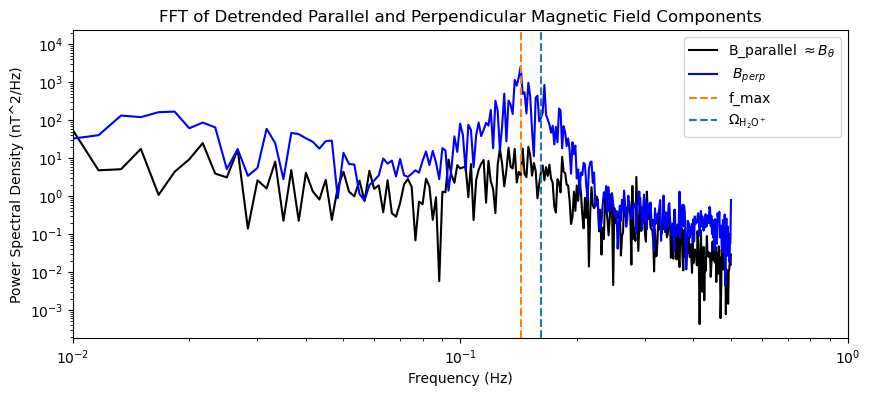

In [24]:
# do the same to dB_parallel and dB_perpendicular components
# col=['dB_parallel','dB_perpendicular']
# F_list=[]
# for c in col:
#     fn=df[c].values
#     N=len(fn)
#     T=1/df['TIME'].diff().dt.total_seconds().mean() # sampling interval in seconds
#     F1 = fft.rfft(fn)
#     freqs = fft.rfftfreq(N,d=T)
#     F_list.append((freqs,F1))  

fn=df['dB_parallel'].values
N=len(fn)
T=1/df['TIME'].diff().dt.total_seconds().mean() # sampling interval in seconds
F_parallel = fft.rfft(fn)
freqs_parallel = fft.rfftfreq(N,d=T)

fn=df['dB_perpendicular_1'].values
F_perpendicular_1 = fft.rfft(fn)
freqs_perpendicular = fft.rfftfreq(N,d=T)   

fn=df['dB_perpendicular_2'].values
F_perpendicular_2 = fft.rfft(fn)
freqs_perpendicular = fft.rfftfreq(N,d=T)  


fn=np.sqrt(df['dB_R'].values**2+df['dB_PHI'].values**2)
F2 = fft.rfft(fn)
freqs_perpendicular = fft.rfftfreq(N,d=T)  

    
    
    
freq=freqs[1]-freqs[0]


color=['black','blue']

fig,ax=plt.subplots(figsize=(10,4))
ax.plot(freqs_parallel,np.abs(F_parallel)**2/(N*freq),label=r'B_parallel $ \approx B_{\theta}$',color=color[0])
ax.plot(freqs_perpendicular,(np.abs(F_perpendicular_1)**2+np.abs(F_perpendicular_2)**2)/(N*freq),label=r' $B_{perp} $',color=color[1])

    
# identify maximum peak in the spectrum and plot a vertical line at that frequency
max_peak_freq = freqs[np.argmax(np.abs(F1)**2/(N*freq))]
ax.axvline(max_peak_freq,color='C1',linestyle='--',label=f'f_max')  
#plot a vertical line at the cyclotron frequency
ax.axvline(cyclotron_freq,color='C0',linestyle='--',label=r'$\Omega_{\mathrm{H_2O^+}}$')    
ax.set_xlabel('Frequency (Hz)')
ax.set_title('FFT of Detrended Parallel and Perpendicular Magnetic Field Components')
ax.set_xscale('log')
ax.set_xlim(1e-2,1e0) # Limit x-axis to Nyquist frequency
ax.set_ylabel('Power Spectral Density (nT^2/Hz)')
ax.set_yscale('log')
# ax.set_ylim(None,5e-2)
ax.legend()
plt.show()


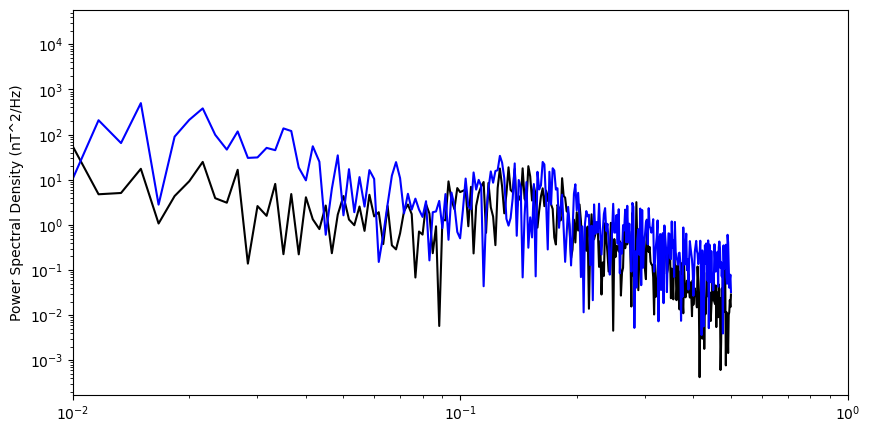

In [13]:
# do the same to dB_parallel and dB_perpendicular components
col=['dB_parallel','dB_perpendicular']
F_list=[]
for c in col:
    fn=df[c].values
    N=len(fn)
    T=1/df['TIME'].diff().dt.total_seconds().mean() # sampling interval in seconds
    F1 = fft.rfft(fn)
    freqs = fft.rfftfreq(N,d=T)
    F_list.append((freqs,F1))  
    
    # plot the spectrum
fig,ax=plt.subplots(figsize=(10,5))
for i,(freqs,F1) in enumerate(F_list):
    ax.plot(freqs,np.abs(F1)**2/(N*freq),label=f'{col[i].strip("d")}',color=color[i])
    
ax.set_xscale('log')
ax.set_xlim(1e-2,1e0) # Limit x-axis to Nyquist frequency
ax.set_ylabel('Power Spectral Density (nT^2/Hz)')
ax.set_yscale('log')


In [272]:
#short time fourier transform
# We adopt 256 sampling points (256 s) to calculate the discrete Fourier transform (DFT) with a sliding window size of 256 samples (256 s) and a 50% (128 s)
T=1/df['TIME'].diff().dt.total_seconds().mean() # sampling interval in seconds.   It should be 1 sec

ff, tt, spec = signal.stft(df['dB_TOTAL'].values, fs=1/T, nperseg=64, noverlap=32)


In [273]:
# resample the time series to match the length of tt using interpolation
df2 = df.copy()
df2["TIME"] = pd.to_datetime(df2["TIME"])
df2 = df2.sort_values("TIME").set_index("TIME")

new_time = pd.date_range(df2.index.min(), df2.index.max(), periods=len(tt))
df_match = df2.reindex(df2.index.union(new_time)).interpolate("time").loc[new_time].reset_index()
df_match = df_match.rename(columns={"index": "TIME"})

In [276]:
1/5e-2


20.0

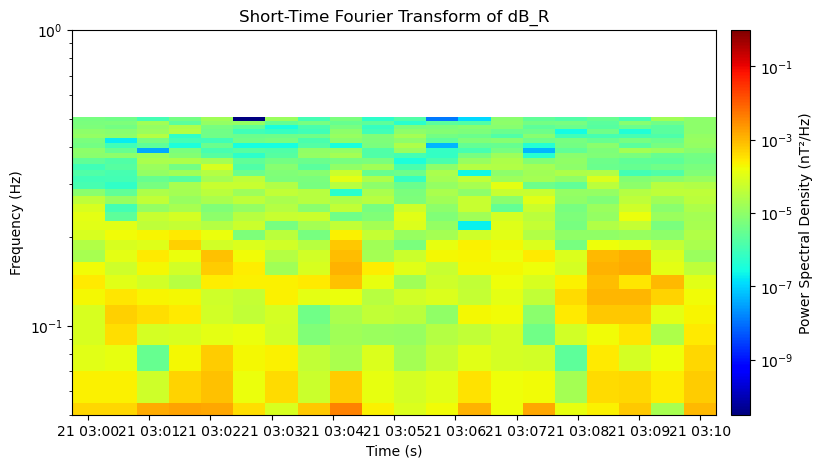

In [275]:

fig,ax=plt.subplots(figsize=(10,5))
pcm = ax.pcolormesh(
    df_match["TIME"], ff, np.abs(spec)**2,
    
    cmap="jet",                     # try: "plasma", "magma", "turbo", "cividis"
    norm=colors.LogNorm(vmin=None, vmax=1e0)  # log color scale
)

cbar = fig.colorbar(pcm, ax=ax, pad=0.02)
cbar.set_label("Power Spectral Density (nT²/Hz)")

ax.set_yscale('log')
ax.set_xlabel('Time (s)')
ax.set_ylabel('Frequency (Hz)')
ax.set_ylim(5e-2,1e-0) # Limit y-axis to Nyquist frequency
ax.set_title('Short-Time Fourier Transform of dB_R')
plt.show()

In [223]:
data=df['dB_R'].values

In [ ]:
data=df['dB_R'].values

Text(0, 0.5, 'Frequency')

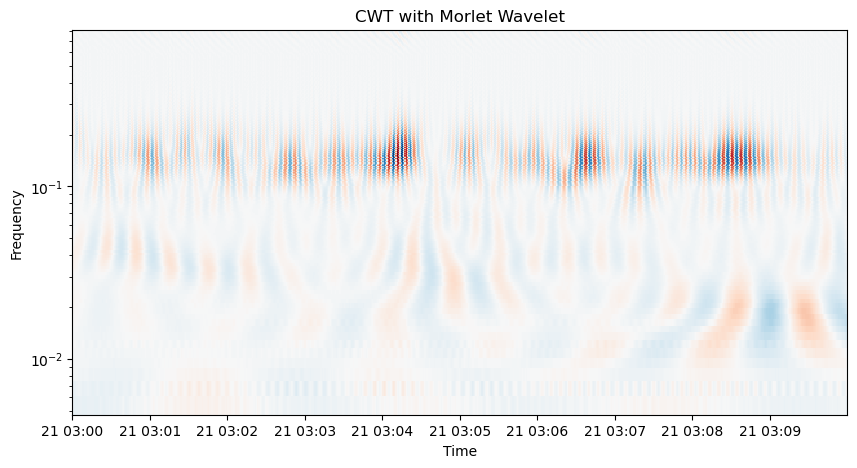

In [230]:

frequencies = np.arange(4,N)/N
scales = 1/frequencies
coefs,freqs = pywt.cwt(data,scales,'morl')

fig,ax=plt.subplots(figsize=(10,5))
ax.pcolormesh(df['TIME'],freqs,coefs,cmap='RdBu_r',shading='nearest'
            #   ,vmin=-2,vmax=2
              )
ax.set_yscale('log')
ax.set_title('CWT with Morlet Wavelet')
ax.set_xlabel('Time')
ax.set_ylabel('Frequency')

## own stuff

In [244]:
start_time=pd.to_datetime('2010-12-21 00:00:00')
end_time=pd.to_datetime('2010-12-22 00:00:00')

df=read_and_process_data(start_time,end_time)

In [250]:
data=df['dB_parallel'].values


Text(0, 0.5, 'Frequency')

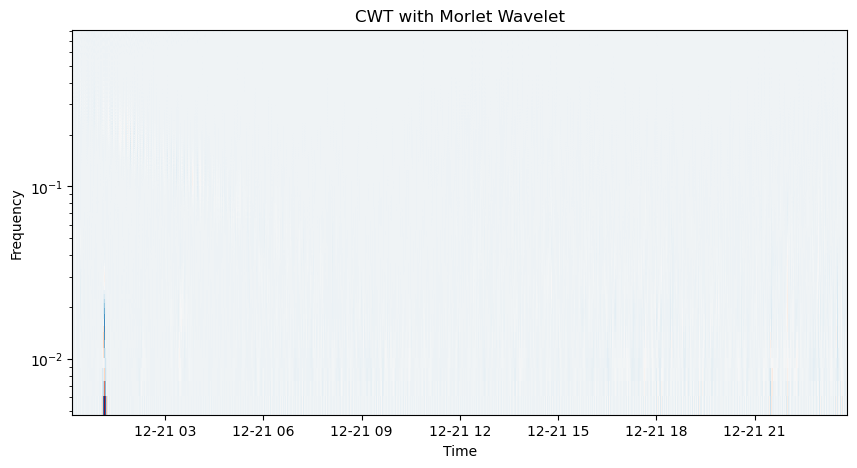

In [246]:
frequencies = np.arange(4,N)/N
scales = 1/frequencies
coefs,freqs = pywt.cwt(data,scales,'morl')

fig,ax=plt.subplots(figsize=(10,5))
ax.pcolormesh(df['TIME'],freqs,coefs,cmap='RdBu_r',shading='nearest'
            #   ,vmin=-2,vmax=2
              )
ax.set_yscale('log')
ax.set_title('CWT with Morlet Wavelet')
ax.set_xlabel('Time')
ax.set_ylabel('Frequency')

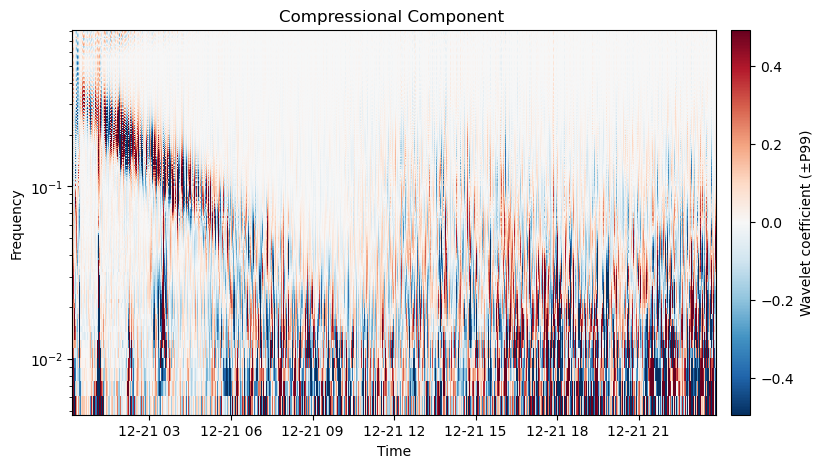

In [253]:

data=df['dB_parallel'].values

# automatic color limits from percentile (robust to outliers)
p = 99  # change to 95/98/99.5 as needed
v = np.nanpercentile(np.abs(coefs), p)
vmin, vmax = -v, v  # symmetric for diverging colormap

fig, ax = plt.subplots(figsize=(10, 5))
pcm = ax.pcolormesh(
    df["TIME"], freqs, coefs,
    cmap="RdBu_r",
    shading="nearest",
    vmin=vmin, vmax=vmax
)

cbar = fig.colorbar(pcm, ax=ax, pad=0.02)
cbar.set_label(f"Wavelet coefficient (±P{p})")

ax.set_yscale("log")
ax.set_title("Compressional Component ")
ax.set_xlabel("Time")
ax.set_ylabel("Frequency")
plt.show()

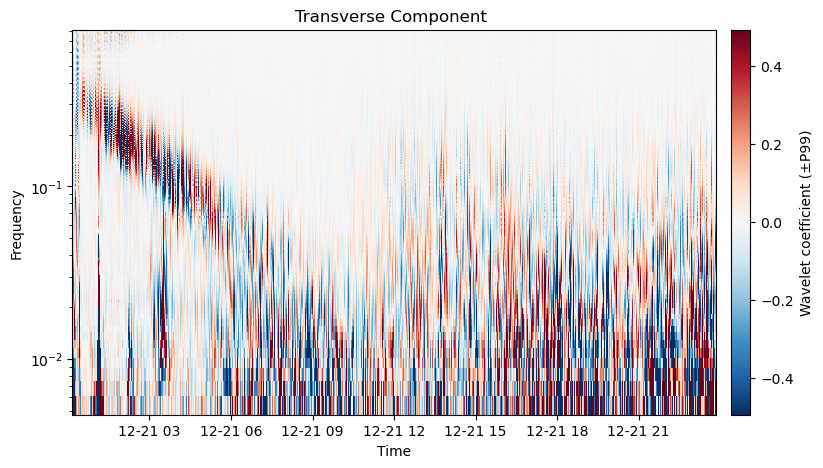

In [254]:

data=df['dB_perpendicular'].values

# automatic color limits from percentile (robust to outliers)
p = 99  # change to 95/98/99.5 as needed
v = np.nanpercentile(np.abs(coefs), p)
vmin, vmax = -v, v  # symmetric for diverging colormap

fig, ax = plt.subplots(figsize=(10, 5))
pcm = ax.pcolormesh(
    df["TIME"], freqs, coefs,
    cmap="RdBu_r",
    shading="nearest",
    vmin=vmin, vmax=vmax
)

cbar = fig.colorbar(pcm, ax=ax, pad=0.02)
cbar.set_label(f"Wavelet coefficient (±P{p})")

ax.set_yscale("log")
ax.set_title("Transverse Component ")
ax.set_xlabel("Time")
ax.set_ylabel("Frequency")
plt.show()

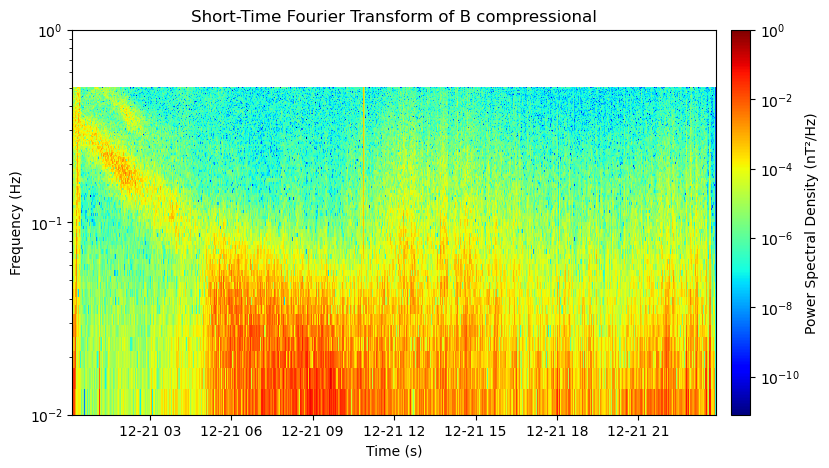

In [247]:
#short time fourier transform
# We adopt 256 sampling points (256 s) to calculate the discrete Fourier transform (DFT) with a sliding window size of 256 samples (256 s) and a 50% (128 s)
T=1/df['TIME'].diff().dt.total_seconds().mean() # sampling interval in seconds.   It should be 1 sec

ff, tt, spec = signal.stft(df['dB_parallel'].values, fs=1/T, nperseg=256, noverlap=128)

# resample the time series to match the length of tt using interpolation
df2 = df.copy()
df2["TIME"] = pd.to_datetime(df2["TIME"])
df2 = df2.sort_values("TIME").set_index("TIME")

new_time = pd.date_range(df2.index.min(), df2.index.max(), periods=len(tt))
df_match = df2.reindex(df2.index.union(new_time)).interpolate("time").loc[new_time].reset_index()
df_match = df_match.rename(columns={"index": "TIME"})


fig,ax=plt.subplots(figsize=(10,5))
pcm = ax.pcolormesh(
    df_match["TIME"], ff, np.abs(spec)**2,
    
    cmap="jet",                     # try: "plasma", "magma", "turbo", "cividis"
    norm=colors.LogNorm(vmin=None, vmax=1e0)  # log color scale
)

cbar = fig.colorbar(pcm, ax=ax, pad=0.02)
cbar.set_label("Power Spectral Density (nT²/Hz)")

ax.set_yscale('log')
ax.set_xlabel('Time (s)')
ax.set_ylabel('Frequency (Hz)')
ax.set_ylim(1e-2,1e-0) # Limit y-axis to Nyquist frequency
ax.set_title('Short-Time Fourier Transform of B compressional')
plt.show()

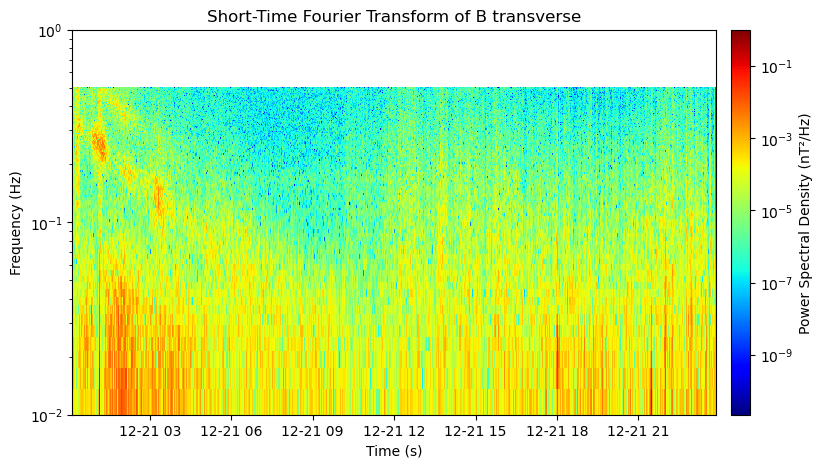

In [248]:
#short time fourier transform
# We adopt 256 sampling points (256 s) to calculate the discrete Fourier transform (DFT) with a sliding window size of 256 samples (256 s) and a 50% (128 s)
T=1/df['TIME'].diff().dt.total_seconds().mean() # sampling interval in seconds.   It should be 1 sec

ff, tt, spec = signal.stft(df['dB_perpendicular'].values, fs=1/T, nperseg=256, noverlap=128)

# resample the time series to match the length of tt using interpolation
df2 = df.copy()
df2["TIME"] = pd.to_datetime(df2["TIME"])
df2 = df2.sort_values("TIME").set_index("TIME")

new_time = pd.date_range(df2.index.min(), df2.index.max(), periods=len(tt))
df_match = df2.reindex(df2.index.union(new_time)).interpolate("time").loc[new_time].reset_index()
df_match = df_match.rename(columns={"index": "TIME"})


fig,ax=plt.subplots(figsize=(10,5))
pcm = ax.pcolormesh(
    df_match["TIME"], ff, np.abs(spec)**2,
    
    cmap="jet",                     # try: "plasma", "magma", "turbo", "cividis"
    norm=colors.LogNorm(vmin=None, vmax=1e0)  # log color scale
)

cbar = fig.colorbar(pcm, ax=ax, pad=0.02)
cbar.set_label("Power Spectral Density (nT²/Hz)")

ax.set_yscale('log')
ax.set_xlabel('Time (s)')
ax.set_ylabel('Frequency (Hz)')
ax.set_ylim(1e-2,1e-0) # Limit y-axis to Nyquist frequency
ax.set_title('Short-Time Fourier Transform of B transverse')
plt.show()

In [257]:
df

,TIME,BR,BTHETA,BPHI,BTOTAL,NPTS,B0_R,B0_THETA,B0_PHI,B0_TOTAL,...,dB_THETA,dB_PHI,dB_TOTAL,b_hat_R,b_hat_THETA,b_hat_PHI,dB_parallel,dB_perpendicular,dB_perpendicular_1,dB_perpendicular_2
0,2010-12-21 00:10:00.500,-11.826,390.812,-0.941,390.992,16,-11.847272,391.162273,-1.160722,391.343364,...,-0.350273,0.219722,0.414031,-0.030273,0.999537,-0.002966,-0.351406,0.218941,0.010638,-0.218682
1,2010-12-21 00:10:01.500,-11.828,390.888,-0.943,391.068,16,-11.847099,391.144351,-1.160406,391.325444,...,-0.256351,0.217406,0.336669,-0.030274,0.999537,-0.002965,-0.257455,0.216939,0.011310,-0.216644
2,2010-12-21 00:10:02.500,-11.831,390.964,-0.945,391.144,16,-11.846747,391.126460,-1.160488,391.307551,...,-0.162460,0.215488,0.270326,-0.030275,0.999537,-0.002966,-0.163501,0.215276,0.010802,-0.215005
3,2010-12-21 00:10:03.500,-11.832,391.193,-0.950,391.373,16,-11.845914,391.108774,-1.160347,391.289848,...,0.084226,0.210347,0.227010,-0.030274,0.999537,-0.002965,0.083142,0.211236,0.016439,-0.210596
4,2010-12-21 00:10:04.500,-11.842,390.811,-0.940,390.992,16,-11.845482,391.091240,-1.160192,391.272309,...,-0.280240,0.220193,0.356415,-0.030274,0.999537,-0.002965,-0.280869,0.219418,-0.005024,-0.219360
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
85135,2010-12-21 23:49:55.500,0.911,8.466,0.562,8.534,8,0.768660,8.300580,0.206288,8.338646,...,0.165420,0.355713,0.417320,0.092180,0.995435,0.024739,0.186586,0.373285,0.125676,-0.351493
85136,2010-12-21 23:49:56.500,0.872,8.442,0.534,8.504,8,0.768253,8.302418,0.205852,8.340428,...,0.139582,0.328148,0.371386,0.092112,0.995443,0.024681,0.156601,0.336755,0.089704,-0.324588
85137,2010-12-21 23:49:57.500,0.845,8.422,0.515,8.480,8,0.767909,8.304187,0.205405,8.342146,...,0.117813,0.309595,0.340106,0.092052,0.995450,0.024623,0.131996,0.313447,0.065217,-0.306587
85138,2010-12-21 23:49:58.500,0.875,8.419,0.530,8.481,8,0.767613,8.305896,0.204989,8.343809,...,0.113104,0.325011,0.360495,0.091998,0.995456,0.024568,0.130454,0.336063,0.095791,-0.322121


Text(0, 0.5, 'B_total (nT)')

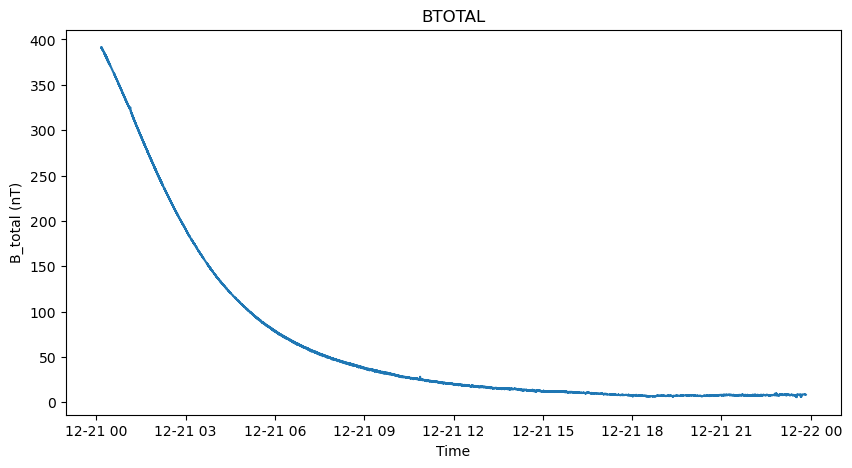

In [259]:
# plot B total
fig,ax=plt.subplots(figsize=(10,5))
ax.plot(df['TIME'],df['BTOTAL'],label='B_total')
ax.set_title("BTOTAL")
ax.set_xlabel("Time")
ax.set_ylabel("B_total (nT)")

## Statistics


In [174]:
start_time=pd.to_datetime('2008-4-11 05:00:00')
end_time=pd.to_datetime('2008-4-11 10:00:00')

df=read_and_process_data(start_time,end_time)

In [175]:
df

,TIME,BR,BTHETA,BPHI,BTOTAL,NPTS,B0_R,B0_THETA,B0_PHI,B0_TOTAL,...,dB_THETA,dB_PHI,dB_TOTAL,b_hat_R,b_hat_THETA,b_hat_PHI,dB_parallel,dB_perpendicular,dB_perpendicular_1,dB_perpendicular_2
0,2008-04-11 05:10:00.500,133.685,124.828,-0.962,182.907,16,133.499116,124.935557,-0.395224,182.841635,...,-0.107557,-0.566776,0.606099,0.730135,0.683299,-0.002162,0.063452,0.602769,0.204237,0.567113
1,2008-04-11 05:10:01.500,133.688,124.843,-0.950,182.918,16,133.495520,124.943704,-0.395684,182.844578,...,-0.100704,-0.554316,0.595362,0.730104,0.683333,-0.002164,0.072915,0.590880,0.203771,0.554632
2,2008-04-11 05:10:02.500,133.680,124.847,-0.955,182.915,9,133.491922,124.951843,-0.396155,182.847514,...,-0.104843,-0.558845,0.598893,0.730072,0.683366,-0.002167,0.066875,0.595147,0.203775,0.559175
3,2008-04-11 05:10:03.500,133.670,124.870,-0.944,182.924,8,133.488322,124.959980,-0.396602,182.850447,...,-0.089980,-0.547398,0.583737,0.730041,0.683400,-0.002169,0.072328,0.579238,0.188580,0.547681
4,2008-04-11 05:10:04.500,133.686,124.854,-0.967,182.925,8,133.484737,124.968104,-0.397071,182.853383,...,-0.114104,-0.569929,0.615098,0.730010,0.683433,-0.002172,0.070179,0.611082,0.219526,0.570289
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
16795,2008-04-11 09:49:55.500,-176.819,231.064,-1.096,290.958,32,-176.861039,230.856194,-1.761494,290.822132,...,0.207806,0.665494,0.698450,-0.608142,0.793805,-0.006057,0.135361,0.685208,0.156656,-0.667060
16796,2008-04-11 09:49:56.500,-176.840,231.067,-1.174,290.974,32,-176.888042,230.854188,-1.761703,290.836963,...,0.212812,0.587703,0.626891,-0.608203,0.793758,-0.006057,0.136142,0.611930,0.164837,-0.589310
16797,2008-04-11 09:49:57.500,-176.865,231.053,-1.351,290.979,32,-176.914920,230.852257,-1.761857,290.851779,...,0.200743,0.410857,0.459993,-0.608265,0.793711,-0.006058,0.126479,0.442263,0.159818,-0.412378
16798,2008-04-11 09:49:58.500,-176.930,231.023,-1.616,290.996,32,-176.941661,230.850432,-1.761792,290.866597,...,0.172568,0.145792,0.226211,-0.608326,0.793664,-0.006057,0.128985,0.185834,0.113553,-0.147105


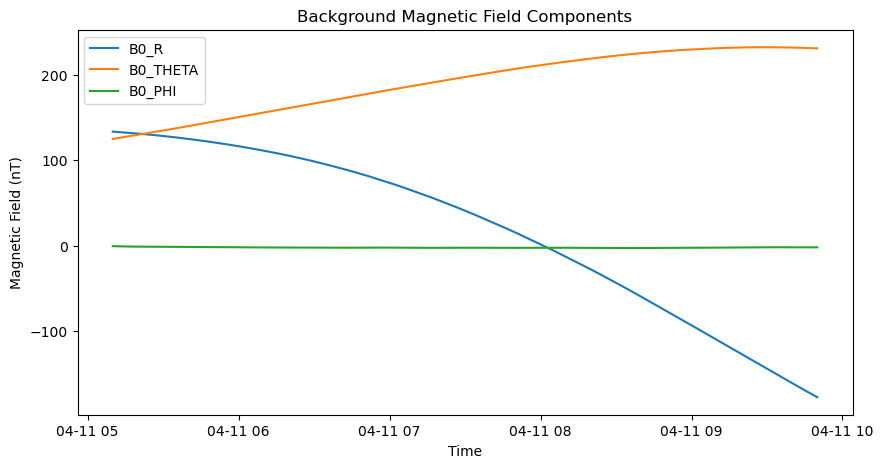

In [176]:
fig,ax=plt.subplots(figsize=(10,5))
ax.plot(df['TIME'],df['B0_R'],label='B0_R')
ax.plot(df['TIME'],df['B0_THETA'],label='B0_THETA')
ax.plot(df['TIME'],df['B0_PHI'],label='B0_PHI')
ax.set_title("Background Magnetic Field Components")
ax.set_xlabel("Time")
ax.set_ylabel("Magnetic Field (nT)")
ax.legend()

In [177]:
# plot dB_R, dB_THETA, dB_PHI. with opacity
fig=go.Figure()
fig.add_trace(go.Scatter(x=pd.to_datetime(df['TIME']),y=df['dB_R'],mode='lines',name='dB_R',line=dict(color='blue'),opacity=0.5))
fig.add_trace(go.Scatter(x=pd.to_datetime(df['TIME']),y=df['dB_THETA'],mode='lines',name='dB_THETA',line=dict(color='red'),opacity=0.5))
fig.add_trace(go.Scatter(x=pd.to_datetime(df['TIME']),y=df['dB_PHI'],mode='lines',name='dB_PHI',line=dict(color='green'),opacity=0.5))
fig.update_layout(height=400,title_text="Detrended Magnetic Field Components")
fig.show()

In [178]:
df['TIME']
# how to sample df['TIME'] uniformly with total number of the same length as tt


0       2008-04-11 05:10:00.500
1       2008-04-11 05:10:01.500
2       2008-04-11 05:10:02.500
3       2008-04-11 05:10:03.500
4       2008-04-11 05:10:04.500
                  ...          
16795   2008-04-11 09:49:55.500
16796   2008-04-11 09:49:56.500
16797   2008-04-11 09:49:57.500
16798   2008-04-11 09:49:58.500
16799   2008-04-11 09:49:59.500
Name: TIME, Length: 16800, dtype: datetime64[ns]

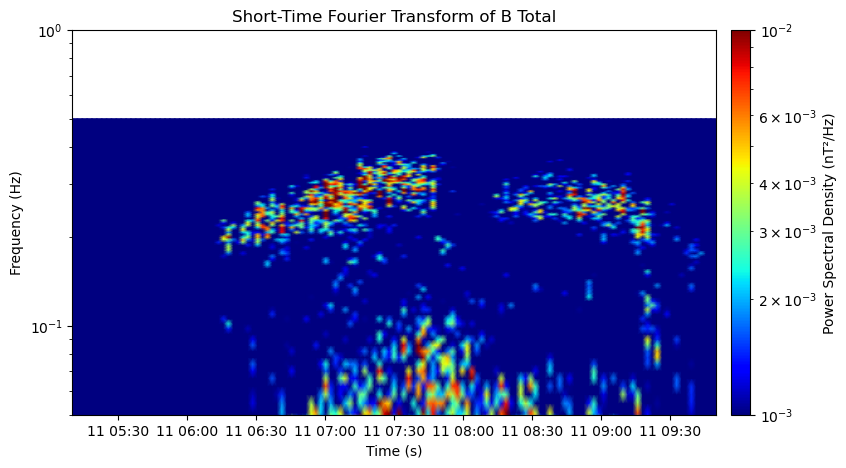

In [205]:
#short time fourier transform
# We adopt 256 sampling points (256 s) to calculate the discrete Fourier transform (DFT) with a sliding window size of 256 samples (256 s) and a 50% (128 s)
T=1/df['TIME'].diff().dt.total_seconds().mean() # sampling interval in seconds.   It should be 1 sec

ff, tt, spec = signal.stft(df['dB_TOTAL'].values, fs=1/T, nperseg=256, noverlap=128)


# resample the time series to match the length of tt using interpolation
df2 = df.copy()
df2["TIME"] = pd.to_datetime(df2["TIME"])
df2 = df2.sort_values("TIME").set_index("TIME")

new_time = pd.date_range(df2.index.min(), df2.index.max(), periods=len(tt))
df_match = df2.reindex(df2.index.union(new_time)).interpolate("time").loc[new_time].reset_index()
df_match = df_match.rename(columns={"index": "TIME"})


fig,ax=plt.subplots(figsize=(10,5))

pcm = ax.pcolormesh(
    df_match["TIME"], ff, np.abs(spec)**2,
    shading="gouraud",
    cmap="jet",                     # try: "plasma", "magma", "turbo", "cividis"
    norm=colors.LogNorm(vmin=1e-3, vmax=1e-2)  # log color scale
)

cbar = fig.colorbar(pcm, ax=ax, pad=0.02)
cbar.set_label("Power Spectral Density (nT²/Hz)")

ax.set_yscale('log')
ax.set_xlabel('Time (s)')
ax.set_ylabel('Frequency (Hz)')
ax.set_ylim(5e-2,1e-0) # Limit y-axis to Nyquist frequency
ax.set_title('Short-Time Fourier Transform of B Total')
plt.show()

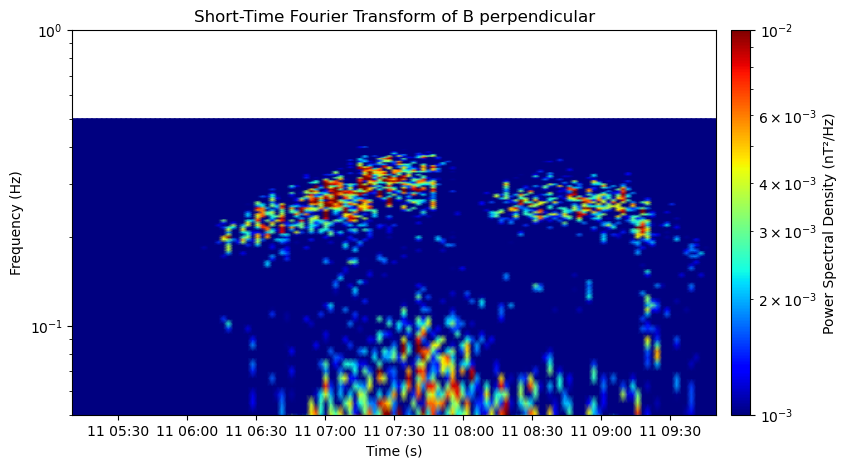

In [206]:
#short time fourier transform
# We adopt 256 sampling points (256 s) to calculate the discrete Fourier transform (DFT) with a sliding window size of 256 samples (256 s) and a 50% (128 s)
T=1/df['TIME'].diff().dt.total_seconds().mean() # sampling interval in seconds.   It should be 1 sec

ff, tt, spec = signal.stft(df['dB_perpendicular'].values, fs=1/T, nperseg=256, noverlap=128)

# resample the time series to match the length of tt using interpolation
df2 = df.copy()
df2["TIME"] = pd.to_datetime(df2["TIME"])
df2 = df2.sort_values("TIME").set_index("TIME")

new_time = pd.date_range(df2.index.min(), df2.index.max(), periods=len(tt))
df_match = df2.reindex(df2.index.union(new_time)).interpolate("time").loc[new_time].reset_index()
df_match = df_match.rename(columns={"index": "TIME"})


fig,ax=plt.subplots(figsize=(10,5))

pcm = ax.pcolormesh(
    df_match["TIME"], ff, np.abs(spec)**2,
    shading="gouraud",
    cmap="jet",                     # try: "plasma", "magma", "turbo", "cividis"
    norm=colors.LogNorm(vmin=1e-3, vmax=1e-2)  # log color scale
)

cbar = fig.colorbar(pcm, ax=ax, pad=0.02)
cbar.set_label("Power Spectral Density (nT²/Hz)")

ax.set_yscale('log')
ax.set_xlabel('Time (s)')
ax.set_ylabel('Frequency (Hz)')
ax.set_ylim(5e-2,1e-0) # Limit y-axis to Nyquist frequency
ax.set_title('Short-Time Fourier Transform of B perpendicular')
plt.show()

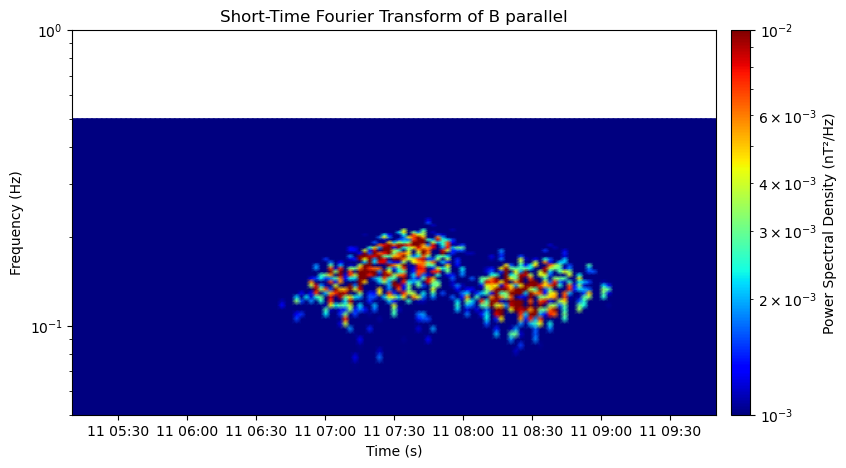

In [207]:
#short time fourier transform
# We adopt 256 sampling points (256 s) to calculate the discrete Fourier transform (DFT) with a sliding window size of 256 samples (256 s) and a 50% (128 s)
T=1/df['TIME'].diff().dt.total_seconds().mean() # sampling interval in seconds.   It should be 1 sec

ff, tt, spec = signal.stft(df['dB_parallel'].values, fs=1/T, nperseg=256, noverlap=128)

# resample the time series to match the length of tt using interpolation
df2 = df.copy()
df2["TIME"] = pd.to_datetime(df2["TIME"])
df2 = df2.sort_values("TIME").set_index("TIME")

new_time = pd.date_range(df2.index.min(), df2.index.max(), periods=len(tt))
df_match = df2.reindex(df2.index.union(new_time)).interpolate("time").loc[new_time].reset_index()
df_match = df_match.rename(columns={"index": "TIME"})


fig,ax=plt.subplots(figsize=(10,5))

pcm = ax.pcolormesh(
    df_match["TIME"], ff, np.abs(spec)**2,
    shading="gouraud",
    cmap="jet",                     # try: "plasma", "magma", "turbo", "cividis"
    norm=colors.LogNorm(vmin=1e-3, vmax=1e-2)  # log color scale
)

cbar = fig.colorbar(pcm, ax=ax, pad=0.02)
cbar.set_label("Power Spectral Density (nT²/Hz)")

ax.set_yscale('log')
ax.set_xlabel('Time (s)')
ax.set_ylabel('Frequency (Hz)')
ax.set_ylim(5e-2,1e-0) # Limit y-axis to Nyquist frequency
ax.set_title('Short-Time Fourier Transform of B parallel')
plt.show()

Mar 25 at 1:46pm
A good start, but your report feels like incomplete work. You have a number of interesting things in your notebook that are not described and interpreted in your report.

Data Description and Motivation (20/20)

The data description is completely clear. The motivation is clear (a replication study). Nonetheless, it would have been helpful to include more background motivation material on EMIC waves at Saturn.

Methodology (17/20)

Your methods for computing the background and field fluctuations are mostly clear. Section 3.2 doesn't describe how B_0 is computed ,but section 4 describes this as a 20-minute running average.

Your FFT analysis methods are clearly described. A problem with FFTs is that they do not apply to non-stationary signals. You have some good results from STFTs in your notebook, but they never made it into the report. The STFT analysis is much more appropriate since you are looking at wave packets that only last a few cycles.

Your report's description of the wavelet analysis is too brief. More detail is needed about what wavelets you chose. I think complex morlet might give you better looking plots than the standard morlet. Your zoomed in plot in the notebook ([230]) looks really nice. You can clearly see the individual wave packets in this version. You could have shown that in the report.

Analysis and Interpretation (40/40)

The analysis of the results you have shown is clear. Your conclusion about the wave frequencies decreases as the satellite orbits away from Saturn and B_0 decreases makes sense.

Something to do beyond the scope of this class would be to attempt to solve the EMIC dispersion relation for the expected wavenumber.

Report Quality (15/20)

The report feels unfinished. The introduction in section 1 is very brief. Section 2.4 is a sentence fragment. The wavelet section is far too brief.